# Assignment 4: IMDB Movie-Review Sentiment Classification
### Comparison of learned and pretrained word embeddings

**Research objective.** This experiment compares two approaches to representing words in a binary sentiment classifier: word embeddings learned directly from labeled IMDB reviews and fixed pretrained GloVe embeddings.

**Study design.** Both approaches use an otherwise identical bidirectional LSTM. Training sample sizes are 100, 500, 2,000, 5,000, and 10,000 reviews; validation uses a fixed set of 10,000 separate reviews. Input sequences are limited to 150 tokens with at most 10,000 vocabulary entries. All reported classification accuracies are validation metrics.

**Scope.** The research evaluates embedding strategies within an RNN-based sequence model. No Transformer was trained. Results are calculated by the notebook from data rather than embedded as predetermined output.


## 1. Libraries and experiment configuration

The configuration fixes the sequence length, embedding dimension, model-training parameters, random seed, and tested training sample sizes.


In [5]:
import os, re, io, html, gc, zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras import layers

SEED = 42
MAX_TOKENS = 10_000
MAX_LENGTH = 150
EMBED_DIM = 100          # GloVe 6B 100-dimensional word vectors
BATCH_SIZE = 128
EPOCHS = 6     
TRAIN_SIZES = [100, 500, 2_000, 5_000, 10_000]
VALIDATION_SIZE = 10_000
OUTPUT_DIR = Path('/kaggle/working')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)
print('GPUs found:', tf.config.list_physical_devices('GPU'))
print('Training sizes:', TRAIN_SIZES)

TensorFlow: 2.21.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Training sizes: [100, 500, 2000, 5000, 10000]


## 2. Dataset discovery

The experiment uses the IMDB movie-review dataset and the 100-dimensional GloVe word vectors. Both data sources are located in the Kaggle input directory.


In [6]:
INPUT_DIR = Path('/kaggle/input')
if not INPUT_DIR.exists():
    raise FileNotFoundError('Required input directory /kaggle/input is missing.')

csv_files = sorted(INPUT_DIR.rglob('*.csv'))
imdb_candidates = [p for p in csv_files if ('imdb' in p.name.lower() or 'movie' in p.name.lower())]
if not imdb_candidates:
    raise FileNotFoundError('IMDB Dataset.csv is not present in the input directory.')
IMDB_PATH = next((p for p in imdb_candidates if p.name.lower() == 'imdb dataset.csv'), imdb_candidates[0])

# GloVe may be provided as plain .txt or in a .zip archive.
glove_txt_files = [p for p in INPUT_DIR.rglob('*.txt') if p.name.lower() == 'glove.6b.100d.txt']
GLOVE_TEXT_PATH = glove_txt_files[0] if glove_txt_files else None
GLOVE_ZIP_PATH = None
GLOVE_ZIP_MEMBER = None
if GLOVE_TEXT_PATH is None:
    for zpath in sorted(INPUT_DIR.rglob('*.zip')):
        try:
            with zipfile.ZipFile(zpath) as archive:
                match = next((n for n in archive.namelist() if n.lower().endswith('glove.6b.100d.txt')), None)
            if match:
                GLOVE_ZIP_PATH, GLOVE_ZIP_MEMBER = zpath, match
                break
        except zipfile.BadZipFile:
            continue

if GLOVE_TEXT_PATH is None and GLOVE_ZIP_PATH is None:
    raise FileNotFoundError(
        'Required glove.6B.100d.txt file is not present in the input directory.'
    )

print('IMDB file:', IMDB_PATH)
print('GloVe file:', GLOVE_TEXT_PATH or f'{GLOVE_ZIP_PATH} -> {GLOVE_ZIP_MEMBER}')

IMDB file: /kaggle/input/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews/IMDB Dataset.csv
GloVe file: /kaggle/input/datasets/danielwillgeorge/glove6b100dtxt/glove.6B.100d.txt


## 3. Movie-review dataset

Reviews are assigned binary labels: positive sentiment is 1 and negative sentiment is 0. HTML formatting artifacts are removed before text vectorization.


In [7]:
raw_df = pd.read_csv(IMDB_PATH)
raw_df.columns = [str(c).strip().lower() for c in raw_df.columns]
if not {'review', 'sentiment'}.issubset(raw_df.columns):
    raise ValueError(f'Expected CSV columns "review" and "sentiment", got: {raw_df.columns.tolist()}')

def clean_review(text):
    """Remove HTML line breaks and decode HTML entities; vectorization comes later."""
    text = html.unescape(str(text))
    return re.sub(r'<br\s*/?>', ' ', text, flags=re.IGNORECASE)

reviews = raw_df[['review', 'sentiment']].dropna().copy()
reviews['review'] = reviews['review'].map(clean_review)
reviews['label'] = reviews['sentiment'].astype(str).str.strip().str.lower().map({'positive': 1, 'negative': 0})
reviews = reviews.dropna(subset=['label'])[['review', 'label']].copy()
reviews['label'] = reviews['label'].astype('int32')

print('Total labeled reviews:', len(reviews))
print('Positive / negative:', reviews['label'].value_counts().sort_index().to_dict())
print('Example review (first 250 characters):', reviews.iloc[0]['review'][:250])
assert len(reviews) >= VALIDATION_SIZE + max(TRAIN_SIZES), 'Dataset is too small for requested splits.'

Total labeled reviews: 50000
Positive / negative: {0: 25000, 1: 25000}
Example review (first 250 characters): One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.  The first thing that struck me about Oz was its brutality and unflinching scenes of violence, 


## 4. Training and validation partition

A fixed 10,000-review validation set is held out from the labeled dataset. Training groups are drawn from the remaining reviews and balanced across positive and negative sentiment. The same validation rows are used for all model comparisons.


In [8]:
training_pool, val_df = train_test_split(
    reviews, test_size=VALIDATION_SIZE, random_state=SEED, stratify=reviews['label']
)
assert set(training_pool.index).isdisjoint(set(val_df.index)), 'Train and validation rows overlap!'
val_df = val_df.reset_index(drop=True)
training_pool = training_pool.reset_index(drop=True)
pos_pool = training_pool[training_pool['label'] == 1].sample(frac=1, random_state=SEED).reset_index(drop=True)
neg_pool = training_pool[training_pool['label'] == 0].sample(frac=1, random_state=SEED).reset_index(drop=True)

assert len(val_df) == 10_000

def get_balanced_training_rows(n):
    if n > 2 * min(len(pos_pool), len(neg_pool)):
        raise ValueError(f'Not enough examples for a balanced training size of {n}')
    half = n // 2
    examples = pd.concat([pos_pool.iloc[:half + n % 2], neg_pool.iloc[:half]], ignore_index=True)
    return examples.sample(frac=1, random_state=SEED + n).reset_index(drop=True)

x_val_text = val_df['review'].astype(str).tolist()
y_val = val_df['label'].to_numpy(dtype=np.float32)
print('Validation examples:', len(val_df))
print('Training pool examples:', len(training_pool))
print('Smallest training sample size:', len(get_balanced_training_rows(100)))

Validation examples: 10000
Training pool examples: 40000
Smallest training sample size: 100


## 5. Pretrained word vectors

GloVe represents each word as 100 numerical values derived from patterns of word use in other texts. These pretrained vectors are held fixed in one of the two sentiment-classification models.


In [9]:
def glove_lines():
    """Yield lines from either an attached .txt or a .zip containing the file."""
    if GLOVE_TEXT_PATH is not None:
        with open(GLOVE_TEXT_PATH, 'r', encoding='utf-8', errors='replace') as f:
            yield from f
    else:
        with zipfile.ZipFile(GLOVE_ZIP_PATH) as zf:
            with zf.open(GLOVE_ZIP_MEMBER, 'r') as bf:
                with io.TextIOWrapper(bf, encoding='utf-8', errors='replace') as f:
                    yield from f

glove_vectors = {}
for line in glove_lines():
    word, separator, numbers = line.rstrip('\n').partition(' ')
    if not separator:
        continue
    vector = np.fromstring(numbers, sep=' ', dtype=np.float32)
    if vector.size == EMBED_DIM:
        glove_vectors[word] = vector

print('GloVe entries loaded:', f'{len(glove_vectors):,}')
assert len(glove_vectors) > 10_000, 'GloVe file looks incomplete or is not 100d.'
print('Example vector dimensions:', glove_vectors['movie'].shape if 'movie' in glove_vectors else 'word not found')

GloVe entries loaded: 400,000
Example vector dimensions: (100,)


## 6. Text vectorization

Review text is lowercased, punctuation is removed, and each review is represented using a sequence of up to 150 token IDs. For each training size, the vocabulary is built exclusively from that training subset. Words outside the vocabulary receive an unknown-token representation.


In [10]:
def prepare_text_data(train_df):
    vectorizer = layers.TextVectorization(
        max_tokens=MAX_TOKENS,
        output_mode='int',
        output_sequence_length=MAX_LENGTH,
        standardize='lower_and_strip_punctuation',
        split='whitespace',
    )
    x_train_text = train_df['review'].astype(str).tolist()
    # Learn the vocabulary from the training subset, never the validation reviews.
    vectorizer.adapt(tf.data.Dataset.from_tensor_slices(x_train_text).batch(256))
    vocab = vectorizer.get_vocabulary()
    x_train = vectorizer(tf.constant(x_train_text)).numpy().astype('int32')
    x_valid = vectorizer(tf.constant(x_val_text)).numpy().astype('int32')
    y_train = train_df['label'].to_numpy(dtype=np.float32)
    assert x_train.shape == (len(train_df), MAX_LENGTH)
    assert x_valid.shape == (VALIDATION_SIZE, MAX_LENGTH)
    assert len(vocab) <= MAX_TOKENS
    return x_train, y_train, x_valid, vocab

def make_glove_matrix(vocab):
    """Match each word in our current vocabulary with its pretrained GloVe vector."""
    matrix = np.zeros((len(vocab), EMBED_DIM), dtype=np.float32)
    covered = 0
    for idx, word in enumerate(vocab):
        if word in glove_vectors:
            matrix[idx] = glove_vectors[word]
            covered += 1
    return matrix, covered

print('Text preparation ready. Every review will have shape:', (MAX_LENGTH,))

Text preparation ready. Every review will have shape: (150,)


## 7. Comparable sequence models

**Learned embedding.** Word vectors start without pretrained semantics and are updated from the sentiment-labeled training reviews.

**Frozen pretrained GloVe.** Word vectors are loaded from GloVe and remain fixed, while the downstream bidirectional LSTM and classification layers are trained.

Both configurations use the same 100-dimensional embedding size, bidirectional LSTM architecture, dropout setting, binary output, and evaluation sample.


In [11]:
def build_lstm_model(vocab_size, pretrained_matrix=None):
    embedding_kwargs = {
        'input_dim': vocab_size,
        'output_dim': EMBED_DIM,
        'mask_zero': True,          # Ignore zero padding at the end of short reviews
        'name': 'word_embedding',
    }
    if pretrained_matrix is not None:
        embedding_kwargs['weights'] = [pretrained_matrix]
        embedding_kwargs['trainable'] = False
    else:
        embedding_kwargs['trainable'] = True

    model = tf.keras.Sequential([
        layers.Input(shape=(MAX_LENGTH,), dtype='int32'),
        layers.Embedding(**embedding_kwargs),
        layers.Bidirectional(layers.LSTM(16), name='bidirectional_lstm'),
        layers.Dropout(0.30),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss='binary_crossentropy',
        metrics=['accuracy'],
    )
    return model

print('Both models share a bidirectional LSTM and classifier. Only the embedding strategy differs.')

Both models share a bidirectional LSTM and classifier. Only the embedding strategy differs.


## 8. Experimental training

For each of the five training sample sizes, the two classifiers are trained under the same training settings. Validation accuracy and loss are recorded at the end of each run. Early stopping monitors validation loss and restores the best model weights. Results may vary with training randomness and the sampled reviews.


In [12]:
records = []
for n in TRAIN_SIZES:
    print('\n' + '=' * 60)
    print(f'EXPERIMENT: {n:,} training reviews; {VALIDATION_SIZE:,} validation reviews')
    current_train = get_balanced_training_rows(n)
    x_train, y_train, x_valid, vocab = prepare_text_data(current_train)
    pretrained_matrix, covered = make_glove_matrix(vocab)
    print(f'Vocabulary: {len(vocab):,} / {MAX_TOKENS:,}; GloVe coverage: {covered:,} tokens')

    for model_type in ['Learned embedding', 'Pretrained GloVe (frozen)']:
        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(SEED)
        use_glove = model_type.startswith('Pretrained')
        model = build_lstm_model(
            vocab_size=len(vocab),
            pretrained_matrix=pretrained_matrix if use_glove else None
        )
        callbacks = [tf.keras.callbacks.EarlyStopping(
            monitor='val_loss', patience=2, min_delta=0.001, restore_best_weights=True
        )]
        print('\nTraining:', model_type)
        history = model.fit(
            x_train, y_train,
            validation_data=(x_valid, y_val),
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            callbacks=callbacks,
            verbose=2,
            shuffle=True,
        )
        val_loss, val_accuracy = model.evaluate(x_valid, y_val, verbose=0)
        records.append({
            'training_reviews': n,
            'model': model_type,
            'validation_accuracy': float(val_accuracy),
            'validation_loss': float(val_loss),
            'epochs_run': len(history.history['loss']),
            'vocab_size': len(vocab),
            'glove_covered_tokens': covered,
        })
        print(f'{model_type} | validation accuracy: {val_accuracy:.2%}')
        del model
        gc.collect()

results = pd.DataFrame(records)
assert len(results) == len(TRAIN_SIZES) * 2
results.to_csv(OUTPUT_DIR / 'assignment4_experiment_results.csv', index=False)
print('\nAll experiments completed; saved CSV results.')


EXPERIMENT: 100 training reviews; 10,000 validation reviews
Vocabulary: 4,836 / 10,000; GloVe coverage: 4,552 tokens

Training: Learned embedding
Epoch 1/6
1/1 - 6s - 6s/step - accuracy: 0.4300 - loss: 0.6948 - val_accuracy: 0.5238 - val_loss: 0.6926
Epoch 2/6
1/1 - 1s - 648ms/step - accuracy: 0.7200 - loss: 0.6882 - val_accuracy: 0.5318 - val_loss: 0.6923
Epoch 3/6
1/1 - 1s - 654ms/step - accuracy: 0.8700 - loss: 0.6815 - val_accuracy: 0.5369 - val_loss: 0.6921
Learned embedding | validation accuracy: 52.38%

Training: Pretrained GloVe (frozen)
Epoch 1/6
1/1 - 3s - 3s/step - accuracy: 0.4600 - loss: 0.7317 - val_accuracy: 0.4988 - val_loss: 0.7031
Epoch 2/6
1/1 - 1s - 641ms/step - accuracy: 0.5100 - loss: 0.7160 - val_accuracy: 0.5051 - val_loss: 0.6967
Epoch 3/6
1/1 - 1s - 660ms/step - accuracy: 0.4900 - loss: 0.6998 - val_accuracy: 0.5119 - val_loss: 0.6945
Epoch 4/6
1/1 - 1s - 631ms/step - accuracy: 0.5300 - loss: 0.6937 - val_accuracy: 0.5156 - val_loss: 0.6945
Epoch 5/6
1/1 - 1s

## 9. Validation accuracy comparison

Validation accuracy is the proportion of the held-out reviews labeled correctly. A positive difference between learned-embedding and GloVe accuracy indicates that the learned embedding performed better at that training size.


In [13]:
comparison = results.pivot(
    index='training_reviews', columns='model', values='validation_accuracy'
).sort_index()
comparison['Difference: learned - GloVe'] = (
    comparison['Learned embedding'] - comparison['Pretrained GloVe (frozen)']
)
comparison['Winner'] = np.where(
    comparison['Difference: learned - GloVe'] > 0,
    'Learned embedding',
    np.where(comparison['Difference: learned - GloVe'] < 0, 'Pretrained GloVe', 'Tie')
)
print('VALIDATION ACCURACY BY TRAINING SIZE')
display(comparison.style.format({
    'Learned embedding': '{:.1%}',
    'Pretrained GloVe (frozen)': '{:.1%}',
    'Difference: learned - GloVe': '{:+.1%}'
}))
comparison.to_csv(OUTPUT_DIR / 'assignment4_comparison_table.csv')

VALIDATION ACCURACY BY TRAINING SIZE


model,Learned embedding,Pretrained GloVe (frozen),Difference: learned - GloVe,Winner
training_reviews,,,,
100,52.4%,51.2%,+1.2%,Learned embedding
500,61.9%,56.7%,+5.2%,Learned embedding
2000,79.3%,67.3%,+11.9%,Learned embedding
5000,81.9%,76.3%,+5.6%,Learned embedding
10000,83.4%,79.5%,+3.8%,Learned embedding


## 10. Accuracy across training-set sizes

The plot compares validation accuracy for the two embedding strategies. The 50% horizontal reference represents chance-level accuracy for a balanced binary classification task.


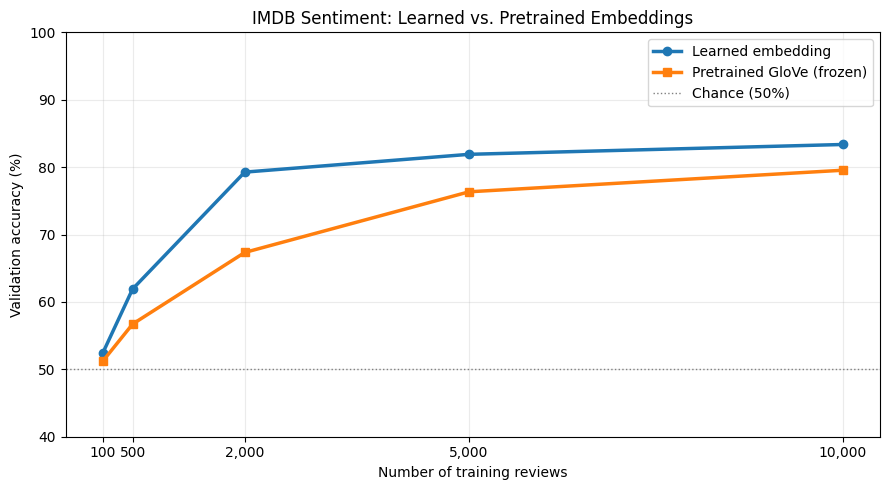

Saved: /kaggle/working/assignment4_accuracy_graph.png


In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(comparison.index, 100 * comparison['Learned embedding'], marker='o',
        linewidth=2.5, label='Learned embedding')
ax.plot(comparison.index, 100 * comparison['Pretrained GloVe (frozen)'], marker='s',
        linewidth=2.5, label='Pretrained GloVe (frozen)')
ax.axhline(50, linestyle=':', linewidth=1, color='gray', label='Chance (50%)')
ax.set_title('IMDB Sentiment: Learned vs. Pretrained Embeddings')
ax.set_xlabel('Number of training reviews')
ax.set_ylabel('Validation accuracy (%)')
ax.set_xticks(TRAIN_SIZES)
ax.set_xticklabels([f'{x:,}' for x in TRAIN_SIZES])
ax.set_ylim(40, 100)
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plot_path = OUTPUT_DIR / 'assignment4_accuracy_graph.png'
fig.savefig(plot_path, dpi=180, bbox_inches='tight')
plt.show()
print('Saved:', plot_path)

## 11. Earliest observed advantage

This analysis identifies the earliest **tested** training size at which learned embeddings exceeded the frozen GloVe baseline. It does not claim to locate an exact crossover threshold between the tested sample sizes.


In [15]:
glove_won_at_100 = comparison.loc[100, 'Winner']
learned_wins = comparison.index[comparison['Difference: learned - GloVe'] > 0].tolist()
if learned_wins:
    crossover_message = (
        f'First TESTED training size where learned embedding beat frozen GloVe: '
        f'{min(learned_wins):,} reviews. '
        'This is not necessarily the exact crossover point between tested sizes.'
    )
else:
    crossover_message = (
        f'No crossover observed for training sizes {TRAIN_SIZES}. '
        'The tested sample sizes do not establish a crossover.'
    )

print('Winner with exactly 100 reviews:', glove_won_at_100)
print(crossover_message)
print('Results are conditional on the sampled data, random seed, and training settings.')

Winner with exactly 100 reviews: Learned embedding
First TESTED training size where learned embedding beat frozen GloVe: 100 reviews. This is not necessarily the exact crossover point between tested sizes.
Results are conditional on the sampled data, random seed, and training settings.


## 12. Structured results summary

The experiment summary presents the dataset, model configuration, observed validation accuracy, primary comparisons, and limitations. All numerical findings are generated from the model results.


In [16]:
lines = [
    '# Assignment 4 — Experiment Summary',
    '',
    '## Setup',
    '- Task: IMDB movie-review sentiment classification (positive vs. negative).',
    f'- Maximum review length: {MAX_LENGTH} tokens.',
    f'- Vocabulary cap: {MAX_TOKENS:,} tokens (learned from each training subset only).',
    f'- Validation set: {VALIDATION_SIZE:,} held-out reviews; fixed across experiments.',
    f'- Training sizes: {", ".join(f"{n:,}" for n in TRAIN_SIZES)}.',
    '- Model: bidirectional LSTM; both approaches share the same architecture.',
    '- Comparison: learned embedding versus 100d GloVe, frozen during training.',
    '',
    '## Actual validation results',
    '',
    '| Training reviews | Learned embedding | Frozen GloVe | Winner |',
    '|---:|---:|---:|---|',
]
for n, row in comparison.iterrows():
    lines.append(
        f'| {n:,} | {row["Learned embedding"]:.1%} | '
        f'{row["Pretrained GloVe (frozen)"]:.1%} | {row["Winner"]} |'
    )
lines += [
    '',
    '## Main findings',
    f'- Winner at 100 reviews: {glove_won_at_100}.',
    f'- {crossover_message}',
    '',
    '## Interpretation',
    '- Across these experiments, observed validation differences reflect the joint effect of the embeddings and the trained bidirectional LSTM.',
    '- A task-trained embedding can adapt word representations to movie-review sentiment, whereas the frozen GloVe vectors are fixed.',
    '- The comparison does not establish why one model wins in a given run; the effect of sampling, model settings, and training randomness remains relevant.',
    '',
    '## Model architecture and study limitations',
    '- The experiment trains bidirectional LSTMs, not Transformers. A Transformer uses attention and positional information rather than recurrence to combine token information.',
    '- The reported scores use a fixed validation set, rather than an independent final test set.',
    '- Generalization beyond this dataset and these training settings was not measured.',

]
summary_path = OUTPUT_DIR / 'assignment4_summary.md'
summary_path.write_text('\n'.join(lines) + '\n', encoding='utf-8')
print(summary_path.read_text(encoding='utf-8'))
print('Saved summary:', summary_path)

# Assignment 4 — Experiment Summary

## Setup
- Task: IMDB movie-review sentiment classification (positive vs. negative).
- Maximum review length: 150 tokens.
- Vocabulary cap: 10,000 tokens (learned from each training subset only).
- Validation set: 10,000 held-out reviews; fixed across experiments.
- Training sizes: 100, 500, 2,000, 5,000, 10,000.
- Model: bidirectional LSTM; both approaches share the same architecture.
- Comparison: learned embedding versus 100d GloVe, frozen during training.

## Actual validation results

| Training reviews | Learned embedding | Frozen GloVe | Winner |
|---:|---:|---:|---|
| 100 | 52.4% | 51.2% | Learned embedding |
| 500 | 61.9% | 56.7% | Learned embedding |
| 2,000 | 79.3% | 67.3% | Learned embedding |
| 5,000 | 81.9% | 76.3% | Learned embedding |
| 10,000 | 83.4% | 79.5% | Learned embedding |

## Main findings
- Winner at 100 reviews: Learned embedding.
- First TESTED training size where learned embedding beat frozen GloVe: 100 reviews. This is 

## 13. Standalone results visualization

An HTML record consolidates the model configuration, observed results table, accuracy chart, findings, and interpretation. This complements the analysis presented in the accompanying PDF report.


In [17]:
from base64 import b64encode
from html import escape as html_escape

report_rows = []
for n, row in comparison.iterrows():
    report_rows.append({
        'Training reviews': f'{n:,}',
        'Learned embedding': f'{row["Learned embedding"]:.1%}',
        'Pretrained GloVe': f'{row["Pretrained GloVe (frozen)"]:.1%}',
        'Winner': row['Winner'],
    })
report_table_html = pd.DataFrame(report_rows).to_html(index=False, border=0, classes='results')
chart_as_base64 = b64encode(plot_path.read_bytes()).decode('ascii')
report_html = f"""<!DOCTYPE html>
<html lang='en'><head><meta charset='utf-8'><title>Assignment 4 - IMDB Embeddings</title>
<style>body{{font-family:Arial,sans-serif;max-width:850px;margin:42px auto;line-height:1.55;color:#203042;padding:0 20px}}
h1,h2{{color:#173756}}table{{border-collapse:collapse;width:100%;margin:20px 0}}
th,td{{padding:11px;border:1px solid #d6e0e9;text-align:left}}th{{background:#edf3f8}}
img{{max-width:100%}}.note{{color:#536577}}</style></head>
<body><h1>Assignment 4: IMDB Review Classification</h1>
<p><strong>Method:</strong> We compared a bidirectional LSTM using newly learned 100-dimensional word embeddings
with the same LSTM using frozen pretrained GloVe 100-dimensional word embeddings.
We used 150-token reviews, a vocabulary limit of 10,000 tokens, and 10,000 fixed validation examples.
Each experiment adapted its vocabulary only on its own training reviews.</p>
<h2>Validation results</h2>{report_table_html}
<h2>Accuracy graph</h2><img alt='Validation accuracy graph' src='data:image/png;base64,{chart_as_base64}' />
<h2>Key findings</h2>
<p><strong>At 100 reviews:</strong> {html_escape(str(glove_won_at_100))} performed best.</p>
<p>{html_escape(crossover_message)}</p>
<h2>Explanation of the approaches</h2>
<p>A learned embedding is a dictionary of word representations trained on the task.
GloVe is a ready-made dictionary learned from a much larger text collection. With little training data,
the pretrained dictionary can provide useful starting information, but the observed winner is determined by the table above.</p>
<p>An LSTM reads words step by step and keeps information about earlier words. A Transformer uses attention to
connect important words across the text and adds position information to keep track of order.
This experiment used an LSTM, not a Transformer.</p>
<p class='note'><strong>Limitations:</strong> These are validation results from one configuration of a bidirectional LSTM. The findings may vary with training samples, model settings, and random seed. An untouched test set would provide additional evidence of generalization.</p>
</body></html>"""
html_path = OUTPUT_DIR / 'assignment4_report.html'
html_path.write_text(report_html, encoding='utf-8')
print('HTML report saved:', html_path)


HTML report saved: /kaggle/working/assignment4_report.html
